# Moduł 2.5 — dwugałęziowa sieć CNN (EEG czasowe + PSD Welcha), LOSO

**Źródło architektury:** praca magisterska *Wykorzystanie analizy fal mózgowych za pomocą sztucznych sieci neuronowych jako elementu interfejsu sterowania protezą dłoni* (E. Bogdał, 2025/2026), rozdz. **4.3.1–4.3.3**, szczególnie **rys. 17 na s. 45**, oraz dołączony notatnik `tuuuuuuuuuuuuuuuuZwidmem-poprawka-testy.ipynb` (komórka tworząca `tf.keras.Model` — tu przepisany na `torch.nn.Module`). Nie jest to jednogałęziowy EEGNet-8,2: **dwa równoległe wejścia raw i PSD, późna fuzja, Dense(64) i sigmoid**.

**Protokół porównawczy:** dane wejściowe wyłącznie z **modułu 1** (`X.npy`, `y.npy`, `groups.npy`, `runs.npy`), **identyczne** zapisane podziały uczestników LOSO co dla CSP/FBCSP/EEGNet/Riemannian. Każdy etap uczący się parametrów (skalery, wagi sieci, early stopping, opcjonalny próg) wykorzystuje tylko uczestników treningowych lub walidacyjnych, **nigdy osobę testową**. Na końcu: metryki per osoba, wykresy, macierz pomyłek, przykładowe predykcje i odtworzenie z zapisanego modelu.

**Ważne różnice wobec pracy magisterskiej, wynikające ze wspólnego modułu 1:**
- Oryginalny notatnik klasyfikuje **T1 vs T0/T2**; tutaj klasyfikujemy **T1 vs T2** i pozytywna klasa ma etykietę **2 (T2)**, tak jak w innych modelach.
- Oryginalny kod pracuje z **160 Hz, oknem [-1, +1] s, wybranymi runami i innym zestawem kanałów**, natomiast tutaj częstotliwość, długość epoki, kanały i runy przychodzą **bez zmian** z modułu 1 (zwykle 128 Hz, 1–3,5 s, 64 kanały, runy 3/4/7/8/11/12).
- W oryginalnym kodzie próg dopasowywany jest do **testu**; tutaj próg jest domyślnie stały 0,50 lub stroi się go **wyłącznie na walidacji**. To niezbędne do poprawnego LOSO.
- Zachowano konstrukcję dwóch torów, jądra konwolucyjne, pooling, ELU, Dropout 0,5, Dense(64), focal loss (γ=2, α=0,75) i wagi klas. Augmentacja jest opcjonalna i dotyczy tylko treningu.

**Implementacja:** architektura została przepisana z TensorFlow/Keras na **PyTorch (`torch.nn`, `DataLoader`, autograd)**. Zachowano wymiary filtrów, pooling, BatchNorm, dropout, focal loss i protokół LOSO. Kolejność wymiarów wejść jest zgodna z PyTorch: `[batch, 1, kanały, czas/częstotliwość]`. Inicjalizacja wag i szczegóły obliczeń mogą prowadzić do innych wartości metryk niż w Keras.

**GPU:** domyślnie `REQUIRE_GPU=True`: notebook zatrzyma trening, jeśli `torch.cuda.is_available()` zwraca `False`. Do testu na CPU ustaw `REQUIRE_GPU=False`. Modele zapisuje się jako `state_dict` w `.pt`, a skalery w `.joblib`.


## 0. Zależności i GPU

Zainstaluj biblioteki w środowisku Jupyter:

```bash
python -m pip install torch mne numpy pandas scikit-learn scipy matplotlib joblib ipykernel
```

Dla karty NVIDIA dobierz wariant PyTorch z CUDA zgodny ze sterownikiem i systemem przy użyciu [oficjalnego konfiguratora](https://pytorch.org/get-started/locally/). Wariant CPU nie będzie używał GPU nawet wtedy, gdy komputer ma kartę NVIDIA. Po instalacji **zrestartuj kernel Jupyter**. Szybki test GPU: `import torch; print(torch.__version__, torch.cuda.is_available())`.

W tym notebooku możesz wykonać krótki test CPU po ustawieniu `REQUIRE_GPU=False` i `MAX_FOLDS=1` (oraz zmniejszeniu `MAX_EPOCHS`).


In [1]:
from pathlib import Path
import gc
import hashlib
import json
import os
import platform
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score)
from mne.time_frequency import psd_array_welch
import mne
import sklearn

try:
    import torch
    from torch import nn
    from torch.nn import functional as nnF
    from torch.utils.data import Dataset, DataLoader
except ImportError as exc:
    raise ImportError("Brak PyTorch. Zainstaluj %pip install torch i zrestartuj kernel.") from exc

# ===== WSPÓLNE DANE Z MODUŁU 1 =====
DATA_BASE = Path.cwd() / "dane_eegmmidb"
MANIFEST_PATH = None   # None = ostatni zestaw z modułu 1; albo ścieżka do manifest.json
RESULTS_BASE = Path.cwd() / "wyniki_modeli" / "EEG_PSD_DUAL_BRANCH"
VERIFY_FILE_HASHES = True

# ===== ARCHITEKTURA ORYGINALNEJ SIECI =====
F1 = 8
DEPTH_MULTIPLIER = 2
F2 = 16
RAW_TEMPORAL_KERNEL = 64
RAW_SEPARABLE_KERNEL = 16
PSD_TEMPORAL_KERNEL = 5
PSD_SEPARABLE_KERNEL = 7
DROPOUT = 0.5
DENSE_UNITS = 64

# ===== WELCH + LOG-PSD (jak w źródłowym kodzie) =====
PSD_FMIN, PSD_FMAX = 8.0, 30.0
PSD_DESIRED_NFFT = 256
PSD_OVERLAP_FRAC = 0.5
PSD_LOG_EPS = 1e-12  # jednostki V**2 / Hz
PSD_CACHE_BATCH = 128

# ===== TRENING: te same FOLDY LOSO co inne modele =====
SEED = 42
MAX_EPOCHS = 100         # w oryginalnym kodzie 300; ustaw 300 dla tego wariantu
PATIENCE = 15            # early stopping wg val_loss (w oryginale bez early stopping)
MIN_DELTA = 1e-4
BATCH_SIZE = 32          # jak w oryginalnym kodzie
LEARNING_RATE = 1e-3     # Adam, domyślne 1e-3
FOCAL_GAMMA, FOCAL_ALPHA = 2.0, 0.75
USE_CLASS_WEIGHTS = True
REFIT_ON_ALL_NON_TEST = True
AUGMENT_TRAIN = False     # dodatkowe próbki tylko w treningu; wyłączone dla czystego porównania
AUGMENT_FRACTION = 0.5  # odsetek epok klasy mniejszościowej do augmentacji
AUGMENT_NOISE_STD_FRACTION = 0.05  # odchylenie względem skali kanału, nie 0.05 V!
AUGMENT_TIME_SHIFT = 20
AUGMENT_AMP_RANGE = (0.9, 1.1)

# ===== WERYFIKOWALNOŚĆ =====
REQUIRE_GPU = True        # zmień na False TYLKO do próby na CPU
TUNE_THRESHOLD = False
DEFAULT_THRESHOLD = 0.50
MIN_VALIDATION_RECALL = 0.20
SAVE_MODELS = True
SAVE_PLOTS = True
SHOW_PLOTS = True
TEST_SUBJECT_TO_SHOW = None
N_SAMPLES = 10
MAX_FOLDS = None         # None = pełne LOSO; np. 2 = TYLKO szybki test integracyjny
OVERWRITE_EXISTING = False

assert F1 == 8 and DEPTH_MULTIPLIER == 2 and F2 == 16 and DENSE_UNITS == 64
assert 0 < DROPOUT < 1 and MAX_EPOCHS > 0 and PATIENCE > 0 and BATCH_SIZE >= 2
assert 0 <= AUGMENT_FRACTION <= 1 and 0 < DEFAULT_THRESHOLD < 1
assert MAX_FOLDS is None or MAX_FOLDS >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| urządzenie:", DEVICE,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "brak")
if REQUIRE_GPU and DEVICE.type != "cuda":
    raise RuntimeError(
        "PyTorch nie wykrywa GPU CUDA. Sprawdź sterownik NVIDIA, zainstaluj wersję "
        "PyTorch z CUDA albo ustaw REQUIRE_GPU=False do próby na CPU."
    )


PyTorch: 2.9.0+cu128 | urządzenie: cuda | GPU: NVIDIA GeForce RTX 5090


## 1. Wczytanie kanonicznego zestawu danych i podziałów LOSO

In [2]:
def read_json(path):
    with Path(path).open(encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path, block_size=1024 * 1024):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            h.update(block)
    return h.hexdigest()


def stable_hash(obj, length=12):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False)
                          .encode("utf-8")).hexdigest()[:length]


if MANIFEST_PATH is None:
    pointer = read_json(DATA_BASE / "ostatni_zestaw.json")
    manifest_path = (DATA_BASE / pointer["manifest_relative_path"]).resolve()
else:
    manifest_path = Path(MANIFEST_PATH).expanduser().resolve()
manifest = read_json(manifest_path)
if manifest.get("schema_version") != "1.0":
    raise ValueError("Wymagany format manifestu danych modułu 1: schema_version=1.0.")
dataset_dir = manifest_path.parent
for key, fileinfo in manifest["files"].items():
    filename = dataset_dir / fileinfo["path"]
    if not filename.is_file():
        raise FileNotFoundError(filename)
    if VERIFY_FILE_HASHES and sha256_file(filename) != fileinfo["sha256"]:
        raise ValueError(f"Zmieniono plik {key} od czasu przygotowania danych: {filename}")

X_all = np.load(dataset_dir / manifest["files"]["X"]["path"], mmap_mode="r")
y_all = np.load(dataset_dir / manifest["files"]["y"]["path"], mmap_mode="r")
groups = np.load(dataset_dir / manifest["files"]["groups"]["path"], mmap_mode="r")
run_all = np.load(dataset_dir / manifest["files"]["runs"]["path"], mmap_mode="r")
splits = read_json(dataset_dir / manifest["files"]["splits"]["path"])
SUBJECT_IDS = list(map(int, manifest["subject_ids"]))
CLASS_NAMES = {int(k): v for k, v in manifest["labels"].items()}
SFREQ = float(manifest["preprocessing"]["target_sfreq"])
N_CHANNELS, N_TIMES = map(int, X_all.shape[1:])

if (X_all.ndim != 3 or X_all.dtype != np.float32 or
        list(X_all.shape) != manifest["X_shape"]):
    raise ValueError("X: oczekiwano float32 [epoki, kanały, czas] z modułu 1.")
if not (len(X_all) == len(y_all) == len(groups) == len(run_all)):
    raise ValueError("Niezgodne liczby epok w X/y/groups/runs.")
if y_all.dtype != np.int8 or groups.dtype != np.int16 or run_all.dtype != np.int8:
    raise ValueError("Niezgodne typy danych.")
if (set(np.unique(y_all).tolist()) != {1, 2} or
        np.unique(groups).tolist() != SUBJECT_IDS or
        manifest["signal_unit"] != "V" or int(manifest["positive_label"]) != 2):
    raise ValueError("Wymagane etykiety 1=T1 i 2=T2 oraz sygnał w V.")
if splits["dataset_id"] != manifest["dataset_id"]:
    raise ValueError("Zapisane podziały LOSO nie pasują do danych.")
if [int(f["test_subject"]) for f in splits["folds"]] != SUBJECT_IDS:
    raise ValueError("Brak któregoś uczestnika w podziałach LOSO.")
for fold in splits["folds"]:
    training = set(map(int, fold["train_subjects_internal"]))
    validation = set(map(int, fold["validation_subjects"]))
    test = set(map(int, fold["test_subjects"]))
    if (training & validation or training & test or validation & test or
            training | validation | test != set(SUBJECT_IDS) or
            test != {int(fold["test_subject"])}):
        raise ValueError(f"Niewłaściwe podziały uczestników dla folda {fold['fold']}")
if N_CHANNELS < 2 or N_TIMES < 64:
    raise ValueError("Niewystarczająca liczba kanałów lub próbek dla oryginalnej sieci.")
if not (0 < PSD_FMIN < PSD_FMAX <= SFREQ / 2):
    raise ValueError("Pasmo PSD musi mieścić się w zakresie Nyquista.")

SELECTED_FOLDS = splits["folds"][:MAX_FOLDS] if MAX_FOLDS is not None else splits["folds"]
IS_FULL_LOSO = len(SELECTED_FOLDS) == len(SUBJECT_IDS)
print("Dane:", manifest["dataset_id"], "| X:", X_all.shape, "| sfreq:", SFREQ)
print("Klasy:", CLASS_NAMES, "| zadania:", manifest["task_types"])
print("Wybrane foldy:", len(SELECTED_FOLDS), "| pełne LOSO:", IS_FULL_LOSO)
if "motor_execution" in manifest["task_types"]:
    warnings.warn("Zbiór zawiera również rzeczywiste wykonywanie ruchu, nie tylko motor imagery.")

Dane: 0a8da1dbe454 | X: (9844, 64, 321) | sfreq: 128.0
Klasy: {1: 'lewa dłoń', 2: 'prawa dłoń'} | zadania: ['motor_execution', 'motor_imagery']
Wybrane foldy: 109 | pełne LOSO: True


/tmp/ipykernel_124459/4141383495.py:79: UserWarning: Zbiór zawiera również rzeczywiste wykonywanie ruchu, nie tylko motor imagery.
  warnings.warn("Zbiór zawiera również rzeczywiste wykonywanie ruchu, nie tylko motor imagery.")


## 2. PSD metodą Welcha — wspólna, deterministyczna cecha wszystkich foldów

Obliczamy **log10(PSD + 1e-12)** dla każdej epoki, każdego kanału i częstotliwości z zakresu **8–30 Hz**, metodą Welcha z **oknem Hann** i **50% nakładaniem** (jak w załączonym kodzie). Wynik zapisujemy raz jako tablicę `.npy` na dysku, żeby 109 foldów nie liczyło PSD ponownie. Samo PSD **nie dopasowuje żadnych parametrów do etykiet**, dlatego wspólny cache nie powoduje przecieku. **Standaryzacja PSD** jest natomiast uczona na uczestnikach treningowych **oddzielnie dla każdego folda**.

Przy domyślnych ustawieniach modułu 1 sygnał jest już przefiltrowany do 8–30 Hz. Ten notebook nie zmienia danych oryginalnego zbioru.

In [3]:
N_FFT = min(int(PSD_DESIRED_NFFT), N_TIMES)
N_OVERLAP = int(N_FFT * PSD_OVERLAP_FRAC)
PSD_CONFIG = {"dataset_id": manifest["dataset_id"], "sfreq": SFREQ,
              "fmin": PSD_FMIN, "fmax": PSD_FMAX, "n_fft": N_FFT,
              "n_per_seg": N_FFT, "n_overlap": N_OVERLAP,
              "window": "hann", "average": "mean", "log_eps": PSD_LOG_EPS}
PSD_CACHE_ID = stable_hash(PSD_CONFIG)
PSD_CACHE_DIR = RESULTS_BASE / "cache_psd"
PSD_CACHE_DIR.mkdir(parents=True, exist_ok=True)
PSD_PATH = PSD_CACHE_DIR / f"{manifest['dataset_id']}_{PSD_CACHE_ID}.npy"
PSD_META_PATH = PSD_PATH.with_suffix(".json")


def psd_welch_log(data):
    result, freqs = psd_array_welch(
        np.asarray(data, dtype=np.float32), sfreq=SFREQ,
        fmin=PSD_FMIN, fmax=PSD_FMAX,
        n_fft=N_FFT, n_per_seg=N_FFT, n_overlap=N_OVERLAP,
        window="hann", average="mean", n_jobs=1, verbose="ERROR")
    return np.log10(np.maximum(result, 0.0) + PSD_LOG_EPS).astype(np.float32), freqs


if PSD_PATH.is_file() and PSD_META_PATH.is_file():
    psd_meta = read_json(PSD_META_PATH)
    if psd_meta["config"] != PSD_CONFIG:
        raise ValueError("Nieprawidłowe metadane cache PSD.")
    PSD_all = np.load(PSD_PATH, mmap_mode="r")
    FREQS = np.asarray(psd_meta["frequencies_hz"], dtype=float)
    if (PSD_all.shape != (len(X_all), N_CHANNELS, len(FREQS)) or
            PSD_all.dtype != np.float32):
        raise ValueError("Cache PSD ma niepoprawny kształt lub dtype.")
    print("Wczytano cache PSD:", PSD_PATH)
elif PSD_PATH.exists() or PSD_META_PATH.exists():
    raise RuntimeError("Niekompletny cache PSD: usuń plik .npy i .json o tej samej nazwie, a potem uruchom ponownie.")
else:
    sample_psd, FREQS = psd_welch_log(X_all[:1])
    N_FREQS = len(FREQS)
    psd_arr = np.lib.format.open_memmap(
        PSD_PATH, mode="w+", dtype=np.float32,
        shape=(len(X_all), N_CHANNELS, N_FREQS))
    for start in range(0, len(X_all), PSD_CACHE_BATCH):
        stop = min(start + PSD_CACHE_BATCH, len(X_all))
        psd_part, freq_part = psd_welch_log(X_all[start:stop])
        if not np.array_equal(freq_part, FREQS):
            raise ValueError("Niespójna siatka częstotliwości PSD.")
        psd_arr[start:stop] = psd_part
        if start == 0 or stop == len(X_all) or stop % (PSD_CACHE_BATCH * 20) == 0:
            print("PSD:", stop, "/", len(X_all))
    psd_arr.flush()
    del psd_arr
    with PSD_META_PATH.open("w", encoding="utf-8") as f:
        json.dump({"config": PSD_CONFIG, "frequencies_hz": FREQS.tolist()}, f, indent=2)
    PSD_all = np.load(PSD_PATH, mmap_mode="r")
N_FREQS = PSD_all.shape[-1]
if N_FREQS < 4:
    raise ValueError("Za mało punktów częstotliwości PSD dla poolingu 1×2 + 1×2.")
print("PSD:", PSD_all.shape, "| f(Hz):", FREQS[0], "..", FREQS[-1])

PSD: 128 / 9844
PSD: 2560 / 9844
PSD: 5120 / 9844
PSD: 7680 / 9844
PSD: 9844 / 9844
PSD: (9844, 64, 45) | f(Hz): 8.0 .. 30.0


## 3. Standaryzacja i podawanie danych partiami

Jak w oryginalnym kodzie, osobno dla obu torów uczymy `StandardScaler` na spłaszczonej macierzy `[kanał × czas]` i `[kanał × częstotliwość]`, a następnie przywracamy wymiary wejściowe CNN. **Każdy scaler jest dopasowywany tylko do indeksów treningowych**; zastosowanie `partial_fit` zmniejsza zapotrzebowanie na RAM. Obie reprezentacje są ładowane partiami, a nie kopiowane w całości do pamięci GPU.

In [4]:
def fit_input_scalers(train_idx, chunk=256):
    raw_scaler = StandardScaler()
    psd_scaler = StandardScaler()
    for start in range(0, len(train_idx), chunk):
        ids = train_idx[start:start+chunk]
        raw = np.asarray(X_all[ids], dtype=np.float32).reshape(len(ids), -1)
        psd = np.asarray(PSD_all[ids], dtype=np.float32).reshape(len(ids), -1)
        raw_scaler.partial_fit(raw)
        psd_scaler.partial_fit(psd)
    return raw_scaler, psd_scaler


def to_inputs(raw_values, psd_values, raw_scaler, psd_scaler):
    """Zwraca NCHW, zgodne z torch.nn.Conv2d: [N, 1, kanały, próbki]."""
    n = len(raw_values)
    raw_scaled = raw_scaler.transform(
        np.asarray(raw_values, dtype=np.float32).reshape(n, -1)
    ).astype(np.float32).reshape(n, 1, N_CHANNELS, N_TIMES)
    psd_scaled = psd_scaler.transform(
        np.asarray(psd_values, dtype=np.float32).reshape(n, -1)
    ).astype(np.float32).reshape(n, 1, N_CHANNELS, N_FREQS)
    return torch.from_numpy(raw_scaled), torch.from_numpy(psd_scaled)


class EEGPSDDataset(Dataset):
    """Indeksy epok; w collate_fn czyta i skaluje całe partie, bez kopiowania całego zbioru."""
    def __init__(self, epoch_indices, raw_scaler, psd_scaler,
                 training, seed, class_weights=None, augment=False):
        self.raw_scaler, self.psd_scaler = raw_scaler, psd_scaler
        self.training = bool(training)
        self.class_weights = class_weights
        self.seed = int(seed)
        self.epoch = 0
        self.batch_no = 0
        self.ids = np.asarray(epoch_indices, dtype=np.int64)
        self.is_augmented = np.zeros(len(self.ids), dtype=bool)
        self.ch_std = np.median(raw_scaler.scale_.reshape(N_CHANNELS, N_TIMES), axis=1)
        if augment and training:
            labels = np.asarray(y_all[self.ids])
            cls, counts = np.unique(labels, return_counts=True)
            minority = cls[int(np.argmin(counts))]
            rng = np.random.default_rng(self.seed)
            candidates = self.ids[labels == minority]
            n_aug = round(len(candidates) * AUGMENT_FRACTION)
            chosen = rng.choice(candidates, size=n_aug, replace=False)
            self.ids = np.concatenate([self.ids, chosen])
            self.is_augmented = np.r_[self.is_augmented, np.ones(len(chosen), dtype=bool)]

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, position):
        # Dane pobieramy wspólnie w collate_batch, zamiast osobno dla każdej epoki.
        return int(position)

    def set_epoch(self, epoch):
        self.epoch = int(epoch)
        self.batch_no = 0

    def collate_batch(self, positions):
        positions = np.asarray(positions, dtype=np.int64)
        idx = self.ids[positions]
        raw = np.array(X_all[idx], dtype=np.float32, copy=True)
        psd = np.array(PSD_all[idx], dtype=np.float32, copy=True)
        augmented = self.is_augmented[positions]
        if augmented.any():
            rng = np.random.default_rng(self.seed + 1000003 * self.epoch + self.batch_no)
            for row in np.flatnonzero(augmented):
                # Sygnał w woltach; szum względny do zmienności kanału.
                raw[row] += rng.normal(
                    0, AUGMENT_NOISE_STD_FRACTION * self.ch_std[:, None],
                    size=raw[row].shape).astype(np.float32)
                shift = int(rng.integers(-AUGMENT_TIME_SHIFT, AUGMENT_TIME_SHIFT + 1))
                raw[row] = np.roll(raw[row], shift, axis=1)
                raw[row] *= rng.uniform(*AUGMENT_AMP_RANGE)
            psd[augmented], _ = psd_welch_log(raw[augmented])
        self.batch_no += 1
        raw_tensor, psd_tensor = to_inputs(raw, psd, self.raw_scaler, self.psd_scaler)
        labels = (np.asarray(y_all[idx]) == 2).astype(np.float32)
        if self.training and self.class_weights is not None:
            weights = np.where(labels == 1, self.class_weights[1],
                               self.class_weights[0]).astype(np.float32)
        else:
            weights = np.ones(len(idx), dtype=np.float32)
        return (raw_tensor, psd_tensor, torch.from_numpy(labels), torch.from_numpy(weights))


def predict_probability_T2(model, idx, raw_scaler, psd_scaler, batch_size=None):
    dataset = EEGPSDDataset(idx, raw_scaler, psd_scaler, training=False, seed=SEED)
    loader = DataLoader(dataset, batch_size=batch_size or BATCH_SIZE,
                        shuffle=False, num_workers=0, collate_fn=dataset.collate_batch,
                        pin_memory=(DEVICE.type == "cuda"))
    model.eval()
    parts = []
    with torch.inference_mode():
        for raw, psd, _, _ in loader:
            prob = model(raw.to(DEVICE, non_blocking=True),
                         psd.to(DEVICE, non_blocking=True))
            parts.append(prob.cpu().numpy().reshape(-1))
    return np.concatenate(parts).astype(np.float32) if parts else np.array([], dtype=np.float32)


## 4. Architektura z pracy mgr — PyTorch (`nn.Module`), identyczny układ warstw i wymiarów filtrów


In [5]:
def binary_focal_loss(y_true, y_pred, sample_weight=None):
    """Focal loss (gamma=2, alpha=0,75 dla T2), średnia ważona jak w Keras."""
    y = y_true.reshape(-1).float()
    p = y_pred.reshape(-1).clamp(min=1e-7, max=1. - 1e-7)
    bce = nnF.binary_cross_entropy(p, y, reduction="none")
    p_t = torch.where(y > 0.5, p, 1. - p)
    alpha_t = y * FOCAL_ALPHA + (1. - y) * (1. - FOCAL_ALPHA)
    loss = alpha_t * (1. - p_t).pow(FOCAL_GAMMA) * bce
    if sample_weight is not None:
        loss = loss * sample_weight.reshape(-1)
    return loss.mean()


def same_temporal_conv(in_channels, out_channels, kernel_width, groups=1):
    """Keras padding='same', w tym asymetryczny padding dla parzystego jądra."""
    left = (kernel_width - 1) // 2
    right = (kernel_width - 1) - left
    return nn.Sequential(
        nn.ZeroPad2d((left, right, 0, 0)),
        nn.Conv2d(in_channels, out_channels, (1, kernel_width),
                  groups=groups, bias=False),
    )


class EEGPSDBranch(nn.Module):
    def __init__(self, n_channels, temporal_kernel, separable_kernel, pool_1, pool_2):
        super().__init__()
        spatial_filters = F1 * DEPTH_MULTIPLIER
        self.temporal = same_temporal_conv(1, F1, temporal_kernel)
        # TensorFlow: BatchNorm momentum=0.99, eps=1e-3.
        # PyTorch stosuje momentum=1-0.99=0.01 dla średniej kroczącej.
        self.bn1 = nn.BatchNorm2d(F1, eps=1e-3, momentum=0.01)
        self.spatial = nn.Conv2d(F1, spatial_filters, (n_channels, 1),
                                 groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(spatial_filters, eps=1e-3, momentum=0.01)
        self.pool1 = nn.AvgPool2d((1, pool_1))
        self.drop1 = nn.Dropout(DROPOUT)
        self.sep_depthwise = same_temporal_conv(
            spatial_filters, spatial_filters, separable_kernel, groups=spatial_filters)
        self.sep_pointwise = nn.Conv2d(spatial_filters, F2, (1, 1), bias=False)
        self.bn3 = nn.BatchNorm2d(F2, eps=1e-3, momentum=0.01)
        self.pool2 = nn.AvgPool2d((1, pool_2))
        self.drop2 = nn.Dropout(DROPOUT)

    def forward(self, x):
        x = self.bn1(self.temporal(x))
        x = self.drop1(self.pool1(nnF.elu(self.bn2(self.spatial(x)))))
        x = self.sep_pointwise(self.sep_depthwise(x))
        x = self.drop2(self.pool2(nnF.elu(self.bn3(x))))
        return torch.flatten(x, start_dim=1)


class DualBranchEEGPSD(nn.Module):
    def __init__(self, n_channels, n_times, n_freqs):
        super().__init__()
        if n_times < 32 or n_freqs < 4:
            raise ValueError("Za mało próbek czasu lub częstotliwości dla poolingu.")
        self.raw_branch = EEGPSDBranch(n_channels, RAW_TEMPORAL_KERNEL,
                                        RAW_SEPARABLE_KERNEL, 4, 8)
        self.psd_branch = EEGPSDBranch(n_channels, PSD_TEMPORAL_KERNEL,
                                        PSD_SEPARABLE_KERNEL, 2, 2)
        flattened_dim = F2 * (n_times // 32 + n_freqs // 4)
        self.dense = nn.Linear(flattened_dim, DENSE_UNITS)
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(DENSE_UNITS, 1)

    def forward(self, raw, psd):
        x = torch.cat((self.raw_branch(raw), self.psd_branch(psd)), dim=1)
        x = self.dropout(nnF.elu(self.dense(x)))
        return torch.sigmoid(self.classifier(x))


def build_master_eeg_psd_network(n_channels=N_CHANNELS, n_times=N_TIMES, n_freqs=N_FREQS):
    return DualBranchEEGPSD(n_channels, n_times, n_freqs)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


seed_everything(SEED)
DEMO_MODEL = build_master_eeg_psd_network()
print(DEMO_MODEL)
print("Wejście RAW:", (None, 1, N_CHANNELS, N_TIMES),
      "| PSD:", (None, 1, N_CHANNELS, N_FREQS))
print("Parametry sieci:", sum(p.numel() for p in DEMO_MODEL.parameters()))
del DEMO_MODEL


DualBranchEEGPSD(
  (raw_branch): EEGPSDBranch(
    (temporal): Sequential(
      (0): ZeroPad2d((31, 32, 0, 0))
      (1): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), bias=False)
    )
    (bn1): BatchNorm2d(8, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
    (spatial): Conv2d(8, 16, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (bn2): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
    (pool1): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (drop1): Dropout(p=0.5, inplace=False)
    (sep_depthwise): Sequential(
      (0): ZeroPad2d((7, 8, 0, 0))
      (1): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), groups=16, bias=False)
    )
    (sep_pointwise): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
    (pool2): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (drop2): Dropout(p=0

## 5. Early stopping, trening końcowy, zapis i metryki

Początkowo uczymy sieć tylko na `train_subjects_internal` i obserwujemy `validation_subjects`. Na podstawie **walidacji** ustalamy liczbę epok i ewentualny próg. Następnie — jak w poprzednim module EEGNet — możemy trenować **od zera** na wszystkich uczestnikach innych niż testowy przez wybraną liczbę epok (`REFIT_ON_ALL_NON_TEST=True`). Osoba testowa nigdy nie służy do wyboru parametrów.

In [6]:
def balanced_weights(train_idx):
    if not USE_CLASS_WEIGHTS:
        return None
    y_train = (np.asarray(y_all[train_idx]) == 2).astype(np.int8)
    weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
    return {0: float(weights[0]), 1: float(weights[1])}


def make_loader(idx, raw_scaler, psd_scaler, training, seed):
    dataset = EEGPSDDataset(
        idx, raw_scaler, psd_scaler, training, seed,
        class_weights=balanced_weights(idx) if training else None,
        augment=AUGMENT_TRAIN if training else False)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=training,
                      num_workers=0, collate_fn=dataset.collate_batch,
                      pin_memory=(DEVICE.type == "cuda"),
                      generator=torch.Generator().manual_seed(seed))


def run_epoch(model, loader, optimizer=None, epoch=1):
    """Trening lub ewaluacja po jednej epoce, z metrykami dla całego zbioru."""
    training = optimizer is not None
    model.train(training)
    loader.dataset.set_epoch(epoch)
    total_loss, total_count = 0., 0
    labels_all, probs_all = [], []
    with torch.set_grad_enabled(training):
        for raw, psd, labels, weights in loader:
            raw = raw.to(DEVICE, non_blocking=True)
            psd = psd.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            weights = weights.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            probs = model(raw, psd).reshape(-1)
            loss = binary_focal_loss(labels, probs,
                                     sample_weight=weights if training else None)
            if training:
                loss.backward()
                optimizer.step()
            size = labels.numel()
            total_loss += float(loss.detach()) * size
            total_count += size
            labels_all.append(labels.detach().cpu().numpy())
            probs_all.append(probs.detach().cpu().numpy())
    if not total_count:
        raise ValueError("Brak próbek do uczenia lub walidacji.")
    y = np.concatenate(labels_all)
    p = np.concatenate(probs_all)
    return {"loss": total_loss / total_count,
            "accuracy": float(accuracy_score(y, p >= 0.5)),
            "auc": float(roc_auc_score(y, p)) if np.unique(y).size == 2 else float("nan")}


def fit_validation_stage(train_idx, val_idx, seed):
    seed_everything(seed)
    scaler_raw, scaler_psd = fit_input_scalers(train_idx)
    train_loader = make_loader(train_idx, scaler_raw, scaler_psd, True, seed)
    val_loader = make_loader(val_idx, scaler_raw, scaler_psd, False, seed)
    model = build_master_eeg_psd_network().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_loss, best_epoch, best_weights, patience_counter = float("inf"), 0, None, 0
    rows = []
    for epoch in range(1, MAX_EPOCHS + 1):
        train_stats = run_epoch(model, train_loader, optimizer=optimizer, epoch=epoch)
        val_stats = run_epoch(model, val_loader, epoch=epoch)
        rows.append({"epoch": epoch,
                     "train_loss": train_stats["loss"], "val_loss": val_stats["loss"],
                     "train_accuracy": train_stats["accuracy"],
                     "val_accuracy": val_stats["accuracy"],
                     "train_auc": train_stats["auc"], "val_auc": val_stats["auc"]})
        if val_stats["loss"] < best_loss - MIN_DELTA:
            best_loss = val_stats["loss"]
            best_epoch = epoch
            best_weights = {key: val.detach().cpu().clone()
                            for key, val in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                break
    model.load_state_dict(best_weights)  # restore_best_weights
    model.eval()
    return model, scaler_raw, scaler_psd, best_epoch, rows


def fit_final_stage(train_idx, n_epochs, seed):
    seed_everything(seed)
    raw_scaler, psd_scaler = fit_input_scalers(train_idx)
    train_loader = make_loader(train_idx, raw_scaler, psd_scaler, True, seed)
    model = build_master_eeg_psd_network().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    rows = []
    for epoch in range(1, n_epochs + 1):
        s = run_epoch(model, train_loader, optimizer=optimizer, epoch=epoch)
        rows.append({"epoch": epoch, "train_loss": s["loss"],
                     "train_accuracy": s["accuracy"], "train_auc": s["auc"],
                     "val_loss": np.nan, "val_accuracy": np.nan, "val_auc": np.nan})
    model.eval()
    return model, raw_scaler, psd_scaler, rows


def labels_from_probability(probabilities, threshold):
    return np.where(np.asarray(probabilities) >= threshold, 2, 1).astype(np.int8)


def choose_threshold(y_val, prob):
    if not TUNE_THRESHOLD:
        return float(DEFAULT_THRESHOLD), "fixed"
    y_val = np.asarray(y_val)
    candidates = []
    for threshold in np.linspace(0.05, 0.95, 91):
        pred = labels_from_probability(prob, threshold)
        precision = precision_score(y_val, pred, pos_label=2, zero_division=0)
        recall = recall_score(y_val, pred, pos_label=2, zero_division=0)
        if recall >= MIN_VALIDATION_RECALL:
            candidates.append((precision, recall, -abs(threshold - 0.5), threshold))
    if not candidates:
        return float(DEFAULT_THRESHOLD), "fallback_0.5"
    return float(max(candidates)[-1]), "validation_optimized"


def calculate_metrics(y_true, y_pred, probs):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[1, 2]).ravel()
    return {
        "precision_T2": float(precision_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "recall_T2": float(recall_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "f1_T2": float(f1_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "auc_T2": float(roc_auc_score((np.asarray(y_true) == 2).astype(int), probs)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "n_test_epochs": int(len(y_true)), "n_predicted_T2": int((y_pred == 2).sum()),
    }


## 6. Rejestr eksperymentu (identyfikator danych, parametrów i wersji bibliotek)

In [7]:
TRAIN_CONFIG = {
    "model": "EEG_PSD_DUAL_BRANCH", "dataset_id": manifest["dataset_id"],
    "architecture": {"raw_conv": [F1, 1, RAW_TEMPORAL_KERNEL], "raw_depth_multiplier": DEPTH_MULTIPLIER,
                     "raw_sepconv": [F2, 1, RAW_SEPARABLE_KERNEL], "raw_pool": [4, 8],
                     "psd_conv": [F1, 1, PSD_TEMPORAL_KERNEL], "psd_sepconv": [F2, 1, PSD_SEPARABLE_KERNEL],
                     "psd_pool": [2, 2], "dense": DENSE_UNITS, "dropout": DROPOUT},
    "psd": PSD_CONFIG,
    "training": {"max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
                 "patience": PATIENCE, "min_delta": MIN_DELTA,
                 "loss": "binary_focal", "gamma": FOCAL_GAMMA, "alpha": FOCAL_ALPHA,
                 "class_weights": USE_CLASS_WEIGHTS, "augment_train": AUGMENT_TRAIN,
                 "augmentation_fraction": AUGMENT_FRACTION,
                 "augmentation_noise_relative": AUGMENT_NOISE_STD_FRACTION,
                 "augmentation_shift_samples": AUGMENT_TIME_SHIFT,
                 "augmentation_amplitude": AUGMENT_AMP_RANGE,
                 "refit_on_all_non_test": REFIT_ON_ALL_NON_TEST},
    "threshold": {"tune_on_validation": TUNE_THRESHOLD,
                  "default": DEFAULT_THRESHOLD, "min_val_recall": MIN_VALIDATION_RECALL},
    "seed": SEED, "max_folds": MAX_FOLDS, "full_loso": IS_FULL_LOSO,
    "gpu_required": REQUIRE_GPU, "positive_label": 2,
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "numpy": np.__version__, "sklearn": sklearn.__version__, "mne": mne.__version__},
}
TRAIN_ID = stable_hash(TRAIN_CONFIG)
OUTPUT_DIR = RESULTS_BASE / manifest["dataset_id"] / TRAIN_ID
MODEL_DIR = OUTPUT_DIR / "modele"
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()) and not OVERWRITE_EXISTING:
    raise FileExistsError(f"Folder eksperymentu już istnieje: {OUTPUT_DIR}. "
                          "Ustaw OVERWRITE_EXISTING=True tylko dla celowego nadpisania wyników.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_MODELS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

experiment_manifest = {
    "experiment_id": TRAIN_ID, "model": "EEG_PSD_DUAL_BRANCH",
    "dataset_id": manifest["dataset_id"],
    "data_manifest_relative_path": os.path.relpath(manifest_path, OUTPUT_DIR),
    "config": TRAIN_CONFIG, "n_folds_expected": len(SELECTED_FOLDS),
    "full_loso": IS_FULL_LOSO,
    # Moduł 3 nie powinien używać joblib.load na pliku .pt.
    "model_format": "pytorch_state_dict_plus_joblib_scalers",
    "model_file_pattern": None,
    "pytorch_model_file_pattern": "modele/S{subject:03d}.pt" if SAVE_MODELS else None,
    "results": {"per_subject": "wyniki_per_subject.csv",
                "predictions": "predykcje_epok.csv",
                "assignments": "podzialy_uczestnikow.csv",
                "history": "historia_uczenia.csv"},
}
with (OUTPUT_DIR / "manifest_modelu.json").open("w", encoding="utf-8") as f:
    json.dump(experiment_manifest, f, ensure_ascii=False, indent=2)
print("Eksperyment:", TRAIN_ID, "| folder:", OUTPUT_DIR)


Eksperyment: 4736adb51c3a | folder: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEG_PSD_DUAL_BRANCH/0a8da1dbe454/4736adb51c3a


## 7. Trening LOSO — sieć dla każdego uczestnika testowego

In [8]:
fold_results, fold_assignments, predictions, history_rows = [], [], [], []
for fold in SELECTED_FOLDS:
    fold_no = int(fold["fold"])
    test_subject = int(fold["test_subject"])
    train_people = list(map(int, fold["train_subjects_internal"]))
    val_people = list(map(int, fold["validation_subjects"]))
    train_idx = np.flatnonzero(np.isin(groups, train_people))
    val_idx = np.flatnonzero(np.isin(groups, val_people))
    test_idx = np.flatnonzero(groups == test_subject)
    non_test_idx = np.flatnonzero(groups != test_subject)
    if len(train_idx) + len(val_idx) + len(test_idx) != len(X_all):
        raise AssertionError("Niekompletny / nakładający się podział epok.")
    if any(set(np.unique(y_all[ids]).tolist()) != {1, 2}
           for ids in (train_idx, val_idx, test_idx)):
        raise ValueError(f"Fold {fold_no}: brak którejś klasy w train/val/test.")

    fold_seed = SEED + test_subject
    val_model, val_raw_scaler, val_psd_scaler, best_epoch, val_history = (
        fit_validation_stage(train_idx, val_idx, seed=fold_seed))
    val_prob = predict_probability_T2(val_model, val_idx, val_raw_scaler, val_psd_scaler)
    threshold, threshold_method = choose_threshold(y_all[val_idx], val_prob)
    for row in val_history:
        history_rows.append({"fold": fold_no, "test_subject": test_subject,
                             "stage": "validation_fit", **row})
    val_pred = labels_from_probability(val_prob, threshold)
    val_precision = float(precision_score(y_all[val_idx], val_pred,
                                          pos_label=2, zero_division=0))
    val_recall = float(recall_score(y_all[val_idx], val_pred,
                                    pos_label=2, zero_division=0))

    if REFIT_ON_ALL_NON_TEST:
        del val_model
        gc.collect()
        model, raw_scaler, psd_scaler, refit_history = (
            fit_final_stage(non_test_idx, best_epoch, seed=fold_seed))
        for row in refit_history:
            history_rows.append({"fold": fold_no, "test_subject": test_subject,
                                 "stage": "final_refit", **row})
    else:
        model, raw_scaler, psd_scaler = val_model, val_raw_scaler, val_psd_scaler

    test_prob = predict_probability_T2(model, test_idx, raw_scaler, psd_scaler)
    test_pred = labels_from_probability(test_prob, threshold)
    metrics = calculate_metrics(y_all[test_idx], test_pred, test_prob)

    if SAVE_MODELS:
        torch.save({"model_state_dict": {key: value.detach().cpu()
                                          for key, value in model.state_dict().items()},
                    "n_channels": N_CHANNELS, "n_times": N_TIMES, "n_freqs": N_FREQS},
                   MODEL_DIR / f"S{test_subject:03d}.pt")
        joblib.dump(raw_scaler, MODEL_DIR / f"S{test_subject:03d}_scaler_raw.joblib")
        joblib.dump(psd_scaler, MODEL_DIR / f"S{test_subject:03d}_scaler_psd.joblib")
        (MODEL_DIR / f"S{test_subject:03d}_metadata.json").write_text(
            json.dumps({"dataset_id": manifest["dataset_id"], "test_subject": test_subject,
                        "best_epoch": best_epoch, "threshold_T2": float(threshold),
                        "n_channels": N_CHANNELS, "n_times": N_TIMES, "n_freqs": N_FREQS,
                        "psd_cache_id": PSD_CACHE_ID}, indent=2), encoding="utf-8")

    fold_results.append({
        "fold": fold_no, "test_subject": test_subject,
        "dataset_id": manifest["dataset_id"],
        "n_train_subjects_internal": len(train_people),
        "n_validation_subjects": len(val_people),
        "n_train_subjects_final": len(SUBJECT_IDS) - 1 if REFIT_ON_ALL_NON_TEST else len(train_people),
        "n_train_epochs_internal": len(train_idx), "n_validation_epochs": len(val_idx),
        "threshold_T2": float(threshold), "threshold_method": threshold_method,
        "validation_precision_T2": val_precision, "validation_recall_T2": val_recall,
        "best_epoch": best_epoch, "epochs_ran_validation": len(val_history),
        **metrics,
    })
    fold_assignments.append({
        "fold": fold_no, "test_subject": test_subject,
        "train_subjects_internal": ",".join(map(str, train_people)),
        "validation_subjects": ",".join(map(str, val_people)),
        "test_subjects": str(test_subject),
        "final_train_subjects": ",".join(map(str, [s for s in SUBJECT_IDS if s != test_subject]
                                                      if REFIT_ON_ALL_NON_TEST else train_people)),
    })
    for i, (idx, pred, prob) in enumerate(zip(test_idx, test_pred, test_prob), start=1):
        predictions.append({"fold": fold_no, "test_subject": test_subject,
                            "test_epoch": i, "global_epoch_index": int(idx),
                            "run": int(run_all[idx]), "y_true": int(y_all[idx]),
                            "y_pred": int(pred), "probability_T2": float(prob),
                            "threshold_T2": float(threshold)})

    pd.DataFrame(fold_results).to_csv(OUTPUT_DIR / "wyniki_per_subject.csv", index=False)
    pd.DataFrame(fold_assignments).to_csv(OUTPUT_DIR / "podzialy_uczestnikow.csv", index=False)
    pd.DataFrame(predictions).to_csv(OUTPUT_DIR / "predykcje_epok.csv", index=False)
    pd.DataFrame(history_rows).to_csv(OUTPUT_DIR / "historia_uczenia.csv", index=False)
    print(f"[{len(fold_results):03d}/{len(SELECTED_FOLDS):03d}] S{test_subject:03d} | "
          f"best epoch {best_epoch} | balanced acc {metrics['balanced_accuracy']:.3f} | "
          f"F1 T2 {metrics['f1_T2']:.3f} | AUC {metrics['auc_T2']:.3f}")
    del model, raw_scaler, psd_scaler, val_raw_scaler, val_psd_scaler
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

results_df = pd.DataFrame(fold_results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(history_rows)
assert results_df["test_subject"].tolist() == [int(f["test_subject"]) for f in SELECTED_FOLDS]
assert predictions_df["global_epoch_index"].is_unique
assert len(predictions_df) == int(np.isin(groups, results_df["test_subject"].values).sum())
if IS_FULL_LOSO:
    assert set(predictions_df["global_epoch_index"]) == set(range(len(X_all)))
    RESULTS_BASE.mkdir(parents=True, exist_ok=True)
    (RESULTS_BASE / "ostatni_eksperyment.json").write_text(json.dumps({
        "experiment_relative_path": str(OUTPUT_DIR.relative_to(RESULTS_BASE)),
        "dataset_id": manifest["dataset_id"], "experiment_id": TRAIN_ID}, indent=2),
        encoding="utf-8")
print("Ukończone foldy:", len(results_df), "| zapisane predykcje:", len(predictions_df))


[001/109] S001 | best epoch 27 | balanced acc 0.704 | F1 T2 0.743 | AUC 0.823
[002/109] S002 | best epoch 3 | balanced acc 0.565 | F1 T2 0.683 | AUC 0.828
[003/109] S003 | best epoch 23 | balanced acc 0.444 | F1 T2 0.603 | AUC 0.394
[004/109] S004 | best epoch 18 | balanced acc 0.478 | F1 T2 0.647 | AUC 0.573
[005/109] S005 | best epoch 20 | balanced acc 0.500 | F1 T2 0.676 | AUC 0.582
[006/109] S006 | best epoch 14 | balanced acc 0.532 | F1 T2 0.667 | AUC 0.586
[007/109] S007 | best epoch 11 | balanced acc 0.870 | F1 T2 0.880 | AUC 0.998
[008/109] S008 | best epoch 21 | balanced acc 0.607 | F1 T2 0.679 | AUC 0.649
[009/109] S009 | best epoch 13 | balanced acc 0.487 | F1 T2 0.631 | AUC 0.635
[010/109] S010 | best epoch 17 | balanced acc 0.613 | F1 T2 0.689 | AUC 0.880
[011/109] S011 | best epoch 2 | balanced acc 0.500 | F1 T2 0.667 | AUC 0.558
[012/109] S012 | best epoch 12 | balanced acc 0.556 | F1 T2 0.692 | AUC 0.806
[013/109] S013 | best epoch 14 | balanced acc 0.521 | F1 T2 0.656 

## 8. Wyniki treningu — podsumowanie metryk dla wszystkich uczestników

Wyniki uczestników:


,test_subject,precision_T2,recall_T2,f1_T2,balanced_accuracy,accuracy,auc_T2,threshold_T2,best_epoch
0,1,0.639344,0.886364,0.742857,0.704051,0.700000,0.823123,0.5,27
1,2,0.524390,0.977273,0.682540,0.564723,0.555556,0.828063,0.5,3
2,3,0.469136,0.844444,0.603175,0.444444,0.444444,0.394074,0.5,23
3,4,0.488636,0.955556,0.646617,0.477778,0.477778,0.572593,0.5,18
4,5,0.511111,1.000000,0.676471,0.500000,0.511111,0.581522,0.5,20
...,...,...,...,...,...,...,...,...,...
104,105,0.511111,1.000000,0.676471,0.500000,0.511111,0.698123,0.5,2
105,106,0.488889,1.000000,0.656716,0.500000,0.488889,0.512846,0.5,3
106,107,0.494253,1.000000,0.661538,0.531915,0.511111,0.796141,0.5,8
107,108,0.630769,0.872340,0.732143,0.657100,0.666667,0.813459,0.5,33


Średnia po osobach (nie po epokach) z 95% CI:


,metric,n_subjects,mean,std,CI95_lower,CI95_upper
0,precision_T2,109,0.531025,0.057429,0.520122,0.541929
1,recall_T2,109,0.946778,0.106919,0.926478,0.967077
2,f1_T2,109,0.674966,0.052101,0.665074,0.684858
3,balanced_accuracy,109,0.550094,0.073033,0.536228,0.563960
4,accuracy,109,0.547331,0.075138,0.533065,0.561596
5,auc_T2,109,0.697680,0.126197,0.673720,0.721639


/tmp/ipykernel_124459/1566197815.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([results_df[col] for col in METRICS], labels=METRICS)


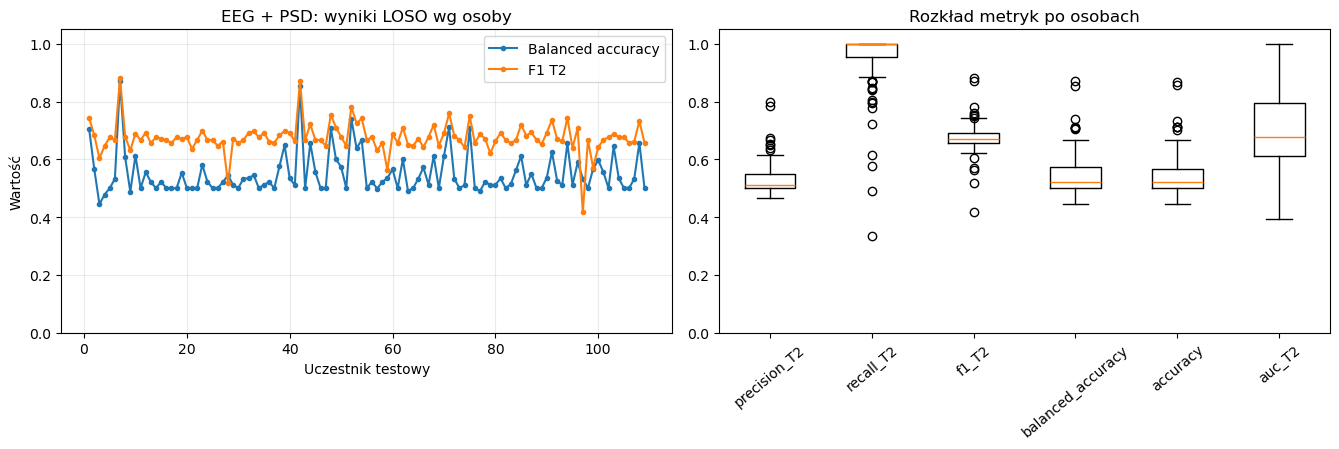

In [9]:
METRICS = ["precision_T2", "recall_T2", "f1_T2", "balanced_accuracy", "accuracy", "auc_T2"]
rows = []
for metric in METRICS:
    vals = results_df[metric].to_numpy(dtype=float)
    mean = float(vals.mean())
    std = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0
    if len(vals) < 2 or np.isclose(std, 0.0):
        ci_low = ci_high = mean
    else:
        ci_low, ci_high = map(float, stats.t.interval(
            0.95, df=len(vals)-1, loc=mean, scale=stats.sem(vals)))
    rows.append({"metric": metric, "n_subjects": len(vals), "mean": mean,
                 "std": std, "CI95_lower": ci_low, "CI95_upper": ci_high})
summary_df = pd.DataFrame(rows)
summary_df.to_csv(OUTPUT_DIR / "podsumowanie_loso.csv", index=False)
print("Wyniki uczestników:")
display(results_df[["test_subject", *METRICS, "threshold_T2", "best_epoch"]])
print("Średnia po osobach (nie po epokach) z 95% CI:")
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
axes[0].plot(results_df["test_subject"], results_df["balanced_accuracy"], "o-", ms=3,
             label="Balanced accuracy")
axes[0].plot(results_df["test_subject"], results_df["f1_T2"], "o-", ms=3,
             label="F1 T2")
axes[0].set(title="EEG + PSD: wyniki LOSO wg osoby", xlabel="Uczestnik testowy",
            ylabel="Wartość", ylim=(0, 1.05))
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].boxplot([results_df[col] for col in METRICS], labels=METRICS)
axes[1].tick_params(axis="x", rotation=40)
axes[1].set(title="Rozkład metryk po osobach", ylim=(0, 1.05))
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "wyniki_loso.png", dpi=150, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 9. Macierz pomyłek i raport klasyfikacji (zagregowane predykcje LOSO)

Zagregowany raport per epoka (oprócz statystyki per osoba):
               precision    recall  f1-score   support

          T1       0.74      0.15      0.25      4950
          T2       0.52      0.95      0.68      4894

    accuracy                           0.55      9844
   macro avg       0.63      0.55      0.46      9844
weighted avg       0.63      0.55      0.46      9844



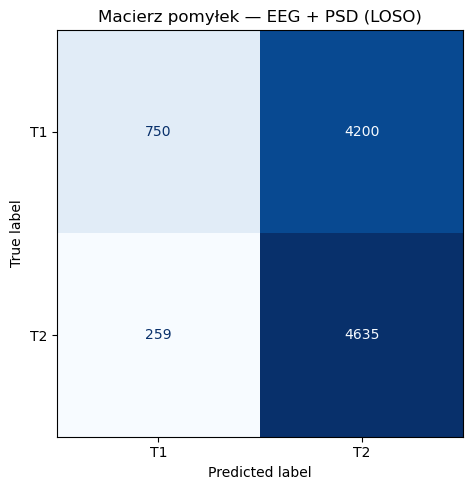

In [10]:
y_true_total = predictions_df["y_true"].to_numpy(dtype=np.int8)
y_pred_total = predictions_df["y_pred"].to_numpy(dtype=np.int8)
report_text = classification_report(y_true_total, y_pred_total, labels=[1, 2],
                                    target_names=["T1", "T2"], zero_division=0)
(OUTPUT_DIR / "raport_klasyfikacji.txt").write_text(report_text, encoding="utf-8")
print("Zagregowany raport per epoka (oprócz statystyki per osoba):\n", report_text)
cm = confusion_matrix(y_true_total, y_pred_total, labels=[1, 2])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["T1", "T2"]).plot(ax=ax,
    cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Macierz pomyłek — EEG + PSD (LOSO)")
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "macierz_pomylek.png", dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 10. Krzywe treningu / walidacji wybranego folda

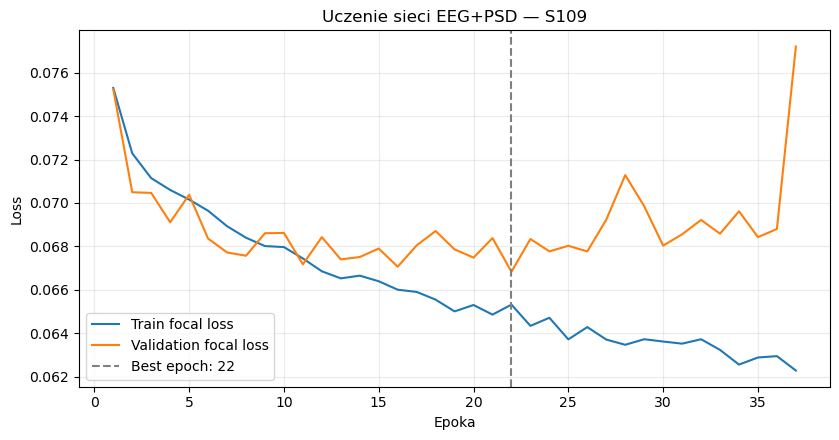

In [11]:
PLOT_SUBJECT = (int(results_df.iloc[-1]["test_subject"])
                if TEST_SUBJECT_TO_SHOW is None else int(TEST_SUBJECT_TO_SHOW))
if PLOT_SUBJECT not in results_df["test_subject"].values:
    raise ValueError("Wybrany testowy uczestnik nie należał do uruchomionych foldów.")
curve = history_df[(history_df["test_subject"] == PLOT_SUBJECT) &
                   (history_df["stage"] == "validation_fit")]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(curve["epoch"], curve["train_loss"], label="Train focal loss")
ax.plot(curve["epoch"], curve["val_loss"], label="Validation focal loss")
best = int(results_df.set_index("test_subject").loc[PLOT_SUBJECT, "best_epoch"])
ax.axvline(best, ls="--", color="gray", label=f"Best epoch: {best}")
ax.set(xlabel="Epoka", ylabel="Loss", title=f"Uczenie sieci EEG+PSD — S{PLOT_SUBJECT:03d}")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / f"krzywa_uczenia_S{PLOT_SUBJECT:03d}.png", dpi=160,
                bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 11. Przykładowe predykcje i sprawdzenie odtwarzania zapisanego modelu

In [12]:
selected = (predictions_df[predictions_df["test_subject"] == PLOT_SUBJECT]
            .sort_values("test_epoch").reset_index(drop=True))
print("Predykcje osoby:", PLOT_SUBJECT, "| liczba epok:", len(selected))
for r in selected.head(N_SAMPLES).itertuples():
    print(f"Epoka {int(r.test_epoch):02d} | R{int(r.run):02d} | "
          f"prawda={CLASS_NAMES[int(r.y_true)]} | "
          f"pred={CLASS_NAMES[int(r.y_pred)]} | "
          f"P(T2)={float(r.probability_T2):.3f} | próg={float(r.threshold_T2):.2f}")

if SAVE_MODELS:
    prefix = MODEL_DIR / f"S{PLOT_SUBJECT:03d}"
    # Odczytuj wyłącznie zaufane checkpointy; weights_only ogranicza deserializację.
    checkpoint = torch.load(str(prefix) + ".pt", map_location="cpu", weights_only=True)
    loaded_model = build_master_eeg_psd_network(
        checkpoint["n_channels"], checkpoint["n_times"], checkpoint["n_freqs"])
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model = loaded_model.to(DEVICE).eval()
    raw_scaler = joblib.load(str(prefix) + "_scaler_raw.joblib")  # tylko zaufane modele!
    psd_scaler = joblib.load(str(prefix) + "_scaler_psd.joblib")
    saved_meta = read_json(str(prefix) + "_metadata.json")
    assert saved_meta["dataset_id"] == manifest["dataset_id"]
    ids = selected["global_epoch_index"].to_numpy(dtype=np.int64)
    restored_probs = predict_probability_T2(loaded_model, ids, raw_scaler, psd_scaler)
    restored_labels = labels_from_probability(restored_probs, saved_meta["threshold_T2"])
    if not np.allclose(restored_probs, selected["probability_T2"].to_numpy(),
                       rtol=2e-5, atol=2e-6):
        raise AssertionError("Zapisany model nie odtwarza predykcji w CSV.")
    if not np.array_equal(restored_labels, selected["y_pred"].to_numpy()):
        raise AssertionError("Zapisany model nie odtwarza etykiet w CSV.")
    print("OK: model .pt i skalery .joblib odtwarzają predykcje dla osoby", PLOT_SUBJECT)
    del loaded_model, checkpoint
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

print("\nWyniki zapisano w:", OUTPUT_DIR)
print("Pliki: wyniki_per_subject.csv, predykcje_epok.csv, podzialy_uczestnikow.csv,")
print("       historia_uczenia.csv, podsumowanie_loso.csv, raport_klasyfikacji.txt")
if SAVE_MODELS:
    print("       modele/Sxxx.pt, modele/Sxxx_scaler_raw.joblib,")
    print("       modele/Sxxx_scaler_psd.joblib, modele/Sxxx_metadata.json")


Predykcje osoby: 109 | liczba epok: 90
Epoka 01 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=0.982 | próg=0.50
Epoka 02 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=0.981 | próg=0.50
Epoka 03 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=0.982 | próg=0.50
Epoka 04 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=0.996 | próg=0.50
Epoka 05 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=0.992 | próg=0.50
Epoka 06 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=0.994 | próg=0.50
Epoka 07 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=0.988 | próg=0.50
Epoka 08 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=0.991 | próg=0.50
Epoka 09 | R03 | prawda=lewa dłoń | pred=prawa dłoń | P(T2)=0.986 | próg=0.50
Epoka 10 | R03 | prawda=prawa dłoń | pred=prawa dłoń | P(T2)=0.992 | próg=0.50
OK: model .pt i skalery .joblib odtwarzają predykcje dla osoby 109

Wyniki zapisano w: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEG_PSD_DUAL_BRANCH/0a8da1db

## 12. Jak porównać z innymi modelami?

- **Moduł 1 zostaje bez zmian**, a `dataset_id` oraz podziały `podzialy_loso.json` są wspólne dla CSP + LDA, FBCSP + LDA, EEGNet-8,2, Tangent Space + Logistic Regression i tego modelu.
- W module 3 ustaw `RESULTS_BASE = Path.cwd() / "wyniki_modeli" / "EEG_PSD_DUAL_BRANCH"`, `SHOW_CSP_PATTERNS = False`, `VERIFY_MODEL_PREDICTIONS = False`. Moduł 3 odczytuje metryki i predykcje; **model PyTorch `.pt` nie może być wczytany przez `joblib.load`**. Odtworzenie sieci (`build_master_eeg_psd_network` + `load_state_dict`) i weryfikację predykcji wykonuje komórka 11. Skalery nadal zapisuje `joblib`.
- Dla uczciwego porównania nie modyfikuj wejścia w module 1 tylko dla tego modelu. Jeśli porównujesz warianty preprocessingowe, nadaj każdemu odrębny `dataset_id` i nie porównuj ich jako tego samego eksperymentu.
- **Nie jest to dokładna reprodukcja wyników z pracy magisterskiej**: w pracy T1 rozróżnia się od reszty (T0/T2), a tu T1 od T2; inne są też okno czasowe, kanały, runy i protokół walidacji. Reprodukujemy **architekturę** i metodę obliczania PSD, stosując rygorystyczny protokół porównania modeli.

**Literatura podstawowa:** E. Bogdał, praca magisterska, 2025/2026, s. 42–46 (rys. 17, s. 45); oryginalny notebook dołączony do prośby; A. Lawhern i in. (2018), EEGNet — pokrewna, ale nie identyczna architektura.
